# Pricing Options with a Binomial Tree
Pricing European and American options with a binomial tree in Python, checked against Black-Scholes.

In [1]:
import math
import matplotlib.pyplot as plt

S0 = 100           # stock price today
K = 100            # strike price
T = 1              # time to expiry (years)
r = 0.05           # risk-free interest rate
sigma = 0.2        # volatility (percent)

# The Payoff
At expirey, an option is worth what you'd get by exercising it.
A call lets you buy at the strike, so it only pays if the stock ends above $K$:
$$C = \max(K - S, \ 0)$$
A put lets you sell at the strike, so it pays only if the stock ends below $K$:
$$P = \max(K - S,\ 0)$$

In [2]:
def payoff(S, K, option_type):
    if option_type == "call":
        return max(S - K, 0)
    else:
        return max(K - S, 0)

## Ups and down moves

The tree splits the time to expiry to $N$ equal steps. At each step the stock either goes up by a factor $u$ or down by a factor $d$:

$$\Delta t = \frac{T}{N}, \qquad u = e^{\sigma\sqrt{\Delta t}}, \qquad d = \frac{1}{u}$$

Since $d = 1/u$, an up move followed by a down move brings the stock back to where it started.

To price the option, we use the probability $p$ of an up move that makes the stock grow at the risk-free rate on average:

$$p = \frac{e^{r\Delta t} - d}{u - d}$$

In [3]:
def tree_parameters(T, r, sigma, N):
    dt = T / N
    u = math.exp(sigma * math.sqrt(dt))
    d = 1 / u
    p = (math.exp(r * dt) - d) / (u - d)
    return dt, u, d, p

## The stock price tree
After $i$ steps with $j$ up moves (and $i - j$ down moves), the stock price is: $$S_{i,j} = S_0 \, u^{j} \, d^{\,i-j}$$ We can store the tree as a list of rows. Row $i$ holds the $i + 1$ possible prices after $i$ steps, so `stock[i][j]` is the price after $i$ steps with $j$ up moves.

In [4]:
def stock_tree(S0, u, d, N):
    stock = []
    for i in range(N + 1):
        row = []
        for j in range(i + 1):
            row.append(S0 * u**j * d**(i - j))
        stock.append(row)
    return stock

# Working Backward to today's price
At expiry, the option is worth its payoff. One step earlier, each node can move to an up node or a down node. Its value is the average of those two, weighted by $p$, and discounted back one step (to account for the time value of money) at the risk-free rate:

$$V_{\text{hold}} = e^{-r\Delta t}\left[\,p\,V_{\text{up}} + (1-p)\,V_{\text{down}}\,\right]$$

Repeating this back to step 0 gives the option's price today.

A **European** option can only be exercised at expiry, so its value is just $V_{\text{hold}}$.

An **American** option can be exercised at any step, so at each node it's worth whichever is bigger, holding or exercising now, in addition, because of its flexibility, the American option is usually equal to or worth more then its european counterpart

In [5]:
def option_tree(S0, K, T, r, sigma, N, option_type, american):
    dt, u, d, p = tree_parameters(T, r, sigma, N)
    stock = stock_tree(S0, u, d, N)
    disc = math.exp(-r * dt)
   
    option = []
    exercise = []
    for i in range(N + 1):
        option.append([0] * (i + 1))
        exercise.append([False] * (i + 1))
    for j in range(N + 1):
        option[N][j] = payoff(stock[N][j], K, option_type)

    for i in range(N - 1, -1, -1):
        for j in range(i + 1):
            hold = disc * (p * option[i + 1][j + 1] + (1 - p) * option[i + 1][j])
            now = payoff(stock[i][j], K, option_type)
            if american and now > hold:
                option[i][j] = now
                exercise[i][j] = True
            else:
                option[i][j] = hold

    return option, exercise


def option_price(S0, K, T, r, sigma, N, option_type, american):
    option, exercise = option_tree(S0, K, T, r, sigma, N, option_type, american)
    return option[0][0]

## Checking against Black-Scholes

Black-Scholes is a formula that gives the exact price of a European option. If my tree is right, its price should get really close to Black-Scholes when I use a lot of steps. The difference between my model and Black-Scholes is that at each step, the stock in my tree can only jump up or down, while Black-Scholes assumes the stock moves smoothly. More steps means smaller jumps, so the tree gets closer to smooth movement.

$$d_1 = \frac{\ln(S_0/K) + (r + \tfrac{1}{2}\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

$$C = S_0\,N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S_0\,N(-d_1)$$

$N(x)$ is the normal CDF, the chance a standard value is less than $x$ (z-score)

In [6]:
def norm_cdf(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def black_scholes(S0, K, T, r, sigma, option_type):
    d1 = (math.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)

    if option_type == "call":
        return S0 * norm_cdf(d1) - K * math.exp(-r * T) * norm_cdf(d2)
    elif option_type == "put":
        return K * math.exp(-r * T) * norm_cdf(-d2) - S0 * norm_cdf(-d1)
    else:
        raise ValueError("option_type must be 'call' or 'put'")

for option_type in ["call", "put"]:
    tree = option_price(S0, K, T, r, sigma, 1000, option_type, False)
    bs = black_scholes(S0, K, T, r, sigma, option_type)
    print("European", option_type, "| tree:", round(tree, 4), "| Black-Scholes:", round(bs, 4))

am = option_price(S0, K, T, r, sigma, 1000, "put", True)
print("American put | tree:", round(am, 4), "| Black-Scholes: no formula")

European call | tree: 10.4486 | Black-Scholes: 10.4506
European put | tree: 5.5715 | Black-Scholes: 5.5735
American put | tree: 6.0896 | Black-Scholes: no formula


## The Tree
This is an American put on a 5-step tree:
- Each circle is a node, placed at its stock price and coloured by what the option is worth there.
- The number inside is the option's value.
- Circles with an orange ring are spots where exercising early is worth more than holding on.

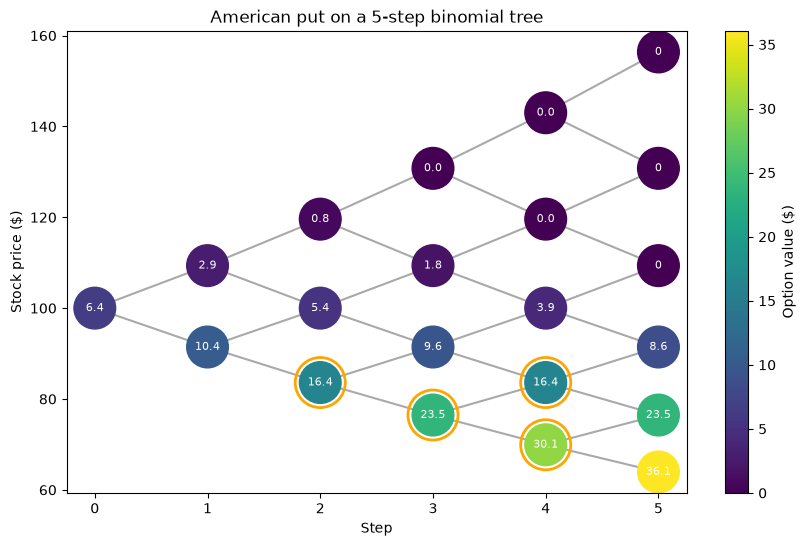

In [7]:
N = 5
dt, u, d, p = tree_parameters(T, r, sigma, N)
stock = stock_tree(S0, u, d, N)
option, exercise = option_tree(S0, K, T, r, sigma, N, "put", True)

plt.figure(figsize=(10, 6))

for i in range(N):
    for j in range(i + 1):
        plt.plot([i, i + 1], [stock[i][j], stock[i + 1][j + 1]], color="darkgrey", zorder=1)
        plt.plot([i, i + 1], [stock[i][j], stock[i + 1][j]], color="darkgrey", zorder=1)


xs = []
ys = []
values = []
for i in range(N + 1):
    for j in range(i + 1):
        xs.append(i)
        ys.append(stock[i][j])
        values.append(option[i][j])

plt.scatter(xs, ys, c=values, cmap="viridis", s=900, zorder=2)
plt.colorbar(label="Option value ($)")

for i in range(N + 1):
    for j in range(i + 1):
        if exercise[i][j]:
            plt.scatter(i, stock[i][j], s=1300, facecolors="none", edgecolors="orange", linewidths=2, zorder=3)
        plt.text(i, stock[i][j], round(option[i][j], 1), ha="center", va="center", color="white", fontsize=8, zorder=4)

plt.xlabel("Step")
plt.ylabel("Stock price ($)")
plt.title("American put on a 5-step binomial tree")
plt.savefig("images/tree.png")
plt.show()

# Does the tree get closer to Black-Scholes
This prices the European call with up to 200 steps and plots it against the Black-Scholes price

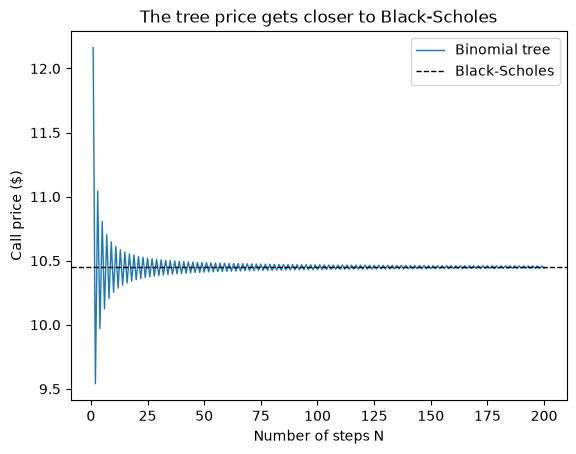

In [8]:
steps = []
prices = []
for n in range(1, 201):
    steps.append(n)
    prices.append(option_price(S0, K, T, r, sigma, n, "call", False))

bs = black_scholes(S0, K, T, r, sigma, "call")

plt.figure()
plt.plot(steps, prices, linewidth=1, label="Binomial tree")
plt.axhline(bs, color="black", linestyle="--", linewidth=1, label="Black-Scholes")
plt.xlabel("Number of steps N")
plt.ylabel("Call price ($)")
plt.title("The tree price gets closer to Black-Scholes")
plt.legend()
plt.savefig("images/convergence.png")
plt.show()

The tree gets closer to Black-Scholes as N goes up (more steps). It zig-zags above and below Black-Scholes because the tree isn't smooth, but with more steps the difference gets smaller.

# Exercise Premium
As previously stated, the American put is worth more than the european one because it can be exercised early. That difference is called the exercise premiun. This will work out that premium for a variety of prices and times to expiry. The brighter the area is, the bigger the premium.

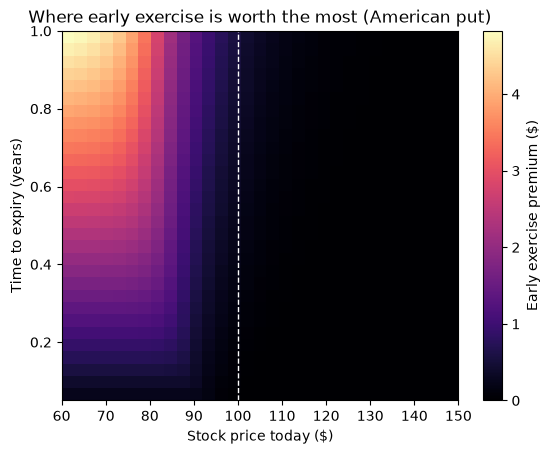

In [10]:
stock_prices = []
for i in range(31):
    stock_prices.append(60 + 3 * i)

times = []
for i in range(30):
    times.append(0.05 + i * 0.95 / 29) 

premium = []
for t_left in times:
    row = []
    for s in stock_prices:
        am = option_price(s, K, t_left, r, sigma, 100, "put", True)
        eu = option_price(s, K, t_left, r, sigma, 100, "put", False)
        row.append(am - eu)
    premium.append(row)

plt.figure()
plt.imshow(premium, origin="lower", aspect="auto", cmap="magma",
           extent=[stock_prices[0], stock_prices[-1], times[0], times[-1]])
plt.colorbar(label="Early exercise premium ($)")
plt.axvline(K, color="white", linestyle="--", linewidth=1)
plt.xlabel("Stock price today ($)")
plt.ylabel("Time to expiry (years)")
plt.title("Where early exercise is worth the most (American put)")
plt.grid(False)
plt.savefig("images/heatmap.png")
plt.show()

The premium is biggest when the stock is way below the strike price with alot of time left till expiry, meaning it's better to take cash now and earn interest on it then wait. When price is above the strike price, the premium is basically 0, because it's not worth exercising anyways. 

## Conclusion
what the model ignores:
- I guessed the volitatility, but no one knows the real future volitality
- The volitilaty doesn't change, which isn't realistic in real markets
- the stock moves in small, regular movements, which wouldn't occur in live markets with things like earnings, crashes, ect

